# 6주차 예습과제 — ResNet 코드 필사
『딥러닝 파이토치 교과서』 6.1.5 ResNet (코드 6-65 ~ 6-89)

- 데이터: 개와 고양이 (dogs-vs-cats)
- 흐름: 데이터 준비 → 기본 블록 / 병목 블록 정의 → ResNet 정의 → 학습 → 테스트 예측

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. 라이브러리 호출 (코드 6-65)
- `namedtuple`: 인덱스뿐 아니라 키 값으로도 접근 가능한 튜플 → 뒤에서 ResNetConfig에 사용
- GPU가 있으면 cuda, 없으면 cpu 사용

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torchvision.models as models

import matplotlib.pyplot as plt
import numpy as np

import copy
from collections import namedtuple
import os
import random
import time

import cv2
from torch.utils.data import DataLoader, Dataset
from PIL import Image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
from collections import namedtuple
Student = namedtuple('Student', ['name', 'age', 'DOB'])   # 네임드튜플 정의
S = Student('홍길동', '19', '187')                          # 네임드튜플에 값을 추가

print("The Student age using index is : ", end="")
print(S[1])        # 인덱스를 이용한 데이터 접근

print("The Student name using keyname is : ", end="")
print(S.name)      # 키 값을 이용한 데이터 접근

The Student age using index is : 19
The Student name using keyname is : 홍길동


## 2. 이미지 데이터 전처리 (코드 6-66)
- `train`: RandomResizedCrop + RandomHorizontalFlip으로 데이터 증강
- `val`: Resize(256) → CenterCrop으로 고정된 변환
- `__call__(img, phase)`: phase에 맞는 전처리 적용

In [4]:
class ImageTransform():
    def __init__(self, resize, mean, std):
        self.data_transform = {
            'train': transforms.Compose([
                transforms.RandomResizedCrop(resize, scale=(0.5, 1.0)),
                transforms.RandomHorizontalFlip(),
                transforms.ToTensor(),
                transforms.Normalize(mean, std)
            ]),   # 훈련 이미지 데이터에 대한 전처리
            'val': transforms.Compose([
                transforms.Resize(256),
                transforms.CenterCrop(resize),
                transforms.ToTensor(),
                transforms.Normalize(mean, std)
            ])    # 검증과 테스트 이미지 데이터에 대한 전처리
        }

    def __call__(self, img, phase):
        return self.data_transform[phase](img)

## 3. 변수에 대한 값 정의 (코드 6-67)
- mean, std는 ImageNet RGB 채널별 평균·표준편차

In [5]:
size = 224
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
batch_size = 32

In [6]:
!pip -q install datasets

import os
from datasets import load_dataset

ds = load_dataset('microsoft/cats_vs_dogs', split='train')
lab_key = 'labels' if 'labels' in ds.features else 'label'

os.makedirs('/content/data/Cat', exist_ok=True)
os.makedirs('/content/data/Dog', exist_ok=True)

labels = ds[lab_key]
cat_idx = [i for i, l in enumerate(labels) if l == 0][:251]
dog_idx = [i for i, l in enumerate(labels) if l == 1][:251]

for n, i in enumerate(cat_idx):
    ds[i]['image'].convert('RGB').save(f'/content/data/Cat/cat.{n}.jpg')
for n, i in enumerate(dog_idx):
    ds[i]['image'].convert('RGB').save(f'/content/data/Dog/dog.{n}.jpg')

print(len(os.listdir('/content/data/Cat')), len(os.listdir('/content/data/Dog')))

README.md:   0%|          | 0.00/8.16k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  330MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  391MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23410 [00:00<?, ? examples/s]

251 251


## 4. 훈련과 테스트 데이터셋 불러오기 (코드 6-68)
- 고양이·개 폴더의 파일 경로를 모아 정렬 → 합치기
- `cv2.imread(i) is not None` → 읽을 수 없는 깨진 이미지 제거

In [7]:
import os
import cv2

cat_directory = r'/content/data/Cat/'
dog_directory = r'/content/data/Dog/'

cat_images_filepaths = sorted([os.path.join(cat_directory, f) for f in os.listdir(cat_directory)])
dog_images_filepaths = sorted([os.path.join(dog_directory, f) for f in os.listdir(dog_directory)])
images_filepaths = [*cat_images_filepaths, *dog_images_filepaths]
correct_images_filepaths = [i for i in images_filepaths if cv2.imread(i) is not None]
print(len(correct_images_filepaths))

502


## 5. 데이터셋을 훈련, 검증, 테스트 용도로 분리 (코드 6-69)
- 훈련 400개 / 검증 92개 / 테스트 10개

In [8]:
random.seed(42)
random.shuffle(correct_images_filepaths)
train_images_filepaths = correct_images_filepaths[:400]
val_images_filepaths = correct_images_filepaths[400:-10]
test_images_filepaths = correct_images_filepaths[-10:]
print(len(train_images_filepaths), len(val_images_filepaths), len(test_images_filepaths))

400 92 10


## 6. 이미지에 대한 레이블 구분 (코드 6-70)
- 파일 이름에서 레이블 추출 → **dog = 1, cat = 0**

In [9]:
class DogvsCatDataset(Dataset):
    def __init__(self, file_list, transform=None, phase='train'):
        self.file_list = file_list
        self.transform = transform
        self.phase = phase

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        img_path = self.file_list[idx]
        img = Image.open(img_path)
        img_transformed = self.transform(img, self.phase)

        label = img_path.split('/')[-1].split('.')[0]
        if label == 'dog':
            label = 1
        elif label == 'cat':
            label = 0
        return img_transformed, label

## 7. 이미지 데이터셋 정의 (코드 6-71)
- 출력: torch.Size([3, 224, 224]) → 컬러(채널 3), 224×224

In [10]:
train_dataset = DogvsCatDataset(train_images_filepaths, transform=ImageTransform(size, mean, std), phase='train')
val_dataset = DogvsCatDataset(val_images_filepaths, transform=ImageTransform(size, mean, std), phase='val')

index = 0
print(train_dataset.__getitem__(index)[0].size())
print(train_dataset.__getitem__(index)[1])

torch.Size([3, 224, 224])
0


## 8. 데이터셋의 데이터를 메모리로 불러오기 (코드 6-72)
- 배치 크기(32)만큼 나눠서 불러옴 → torch.Size([32, 3, 224, 224])

In [11]:
train_iterator = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_iterator = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
dataloader_dict = {'train': train_iterator, 'val': valid_iterator}

batch_iterator = iter(train_iterator)
inputs, label = next(batch_iterator)
print(inputs.size())
print(label)

torch.Size([32, 3, 224, 224])
tensor([1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1,
        1, 0, 1, 1, 1, 1, 1, 1])


## 9. 기본 블록 정의 (코드 6-73)
- ResNet18, ResNet34에서 사용 / 3×3 합성곱 두 개 / `expansion = 1`
- ① downsample: 입력과 출력 크기가 다를 때 숏컷 쪽을 1×1 합성곱(stride) + BN으로 맞춤
- ② `x += i`: 아이덴티티 매핑(스킵 연결) 적용

In [12]:
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1, downsample=False):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                               stride=stride, padding=1, bias=False)   # 3×3 합성곱층
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                               stride=1, padding=1, bias=False)        # 3×3 합성곱층
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

        if downsample:   # ① 다운샘플 적용
            conv = nn.Conv2d(in_channels, out_channels, kernel_size=1,
                             stride=stride, bias=False)
            bn = nn.BatchNorm2d(out_channels)
            downsample = nn.Sequential(conv, bn)
        else:
            downsample = None
        self.downsample = downsample

    def forward(self, x):
        i = x
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.conv2(x)
        x = self.bn2(x)

        if self.downsample is not None:
            i = self.downsample(i)

        x += i   # ② 아이덴티티 매핑 적용
        x = self.relu(x)

        return x

## 10. 병목 블록 정의 (코드 6-74)
- ResNet50, ResNet101, ResNet152에서 사용 / 1×1 → 3×3 → 1×1 합성곱
- `expansion = 4`: 병목 블록을 정의하기 위한 하이퍼파라미터 (출력 채널 4배)

In [13]:
class Bottleneck(nn.Module):
    expansion = 4   # ResNet에서 병목 블록을 정의하기 위한 하이퍼파라미터

    def __init__(self, in_channels, out_channels, stride=1, downsample=False):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=1,
                               stride=1, bias=False)                   # 1×1 합성곱층
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                               stride=stride, padding=1, bias=False)   # 3×3 합성곱층
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.conv3 = nn.Conv2d(out_channels, self.expansion*out_channels,
                               kernel_size=1, stride=1, bias=False)    # 1×1 합성곱층 (다음 계층의 입력 채널 수와 일치하도록)
        self.bn3 = nn.BatchNorm2d(self.expansion*out_channels)
        self.relu = nn.ReLU(inplace=True)

        if downsample:
            conv = nn.Conv2d(in_channels, self.expansion*out_channels, kernel_size=1,
                             stride=stride, bias=False)
            bn = nn.BatchNorm2d(self.expansion*out_channels)
            downsample = nn.Sequential(conv, bn)
        else:
            downsample = None
        self.downsample = downsample

    def forward(self, x):
        i = x
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu(x)
        x = self.conv3(x)
        x = self.bn3(x)

        if self.downsample is not None:
            i = self.downsample(i)

        x += i
        x = self.relu(x)
        return x

## 11. ResNet 모델 네트워크 (코드 6-75)
- `config`로 block, n_blocks, channels를 받아 모델별 구조를 만듦
- `get_resnet_layer`: 블록을 n_blocks만큼 쌓아 layer 하나를 만드는 함수
  - in_channels ≠ block.expansion × channels 이면 첫 블록에 downsample 적용
- ① `zero_init_residual`: 각 레지듀얼 분기의 마지막 BN을 0으로 초기화 → 성능 0.2~0.3% 향상

In [14]:
class ResNet(nn.Module):
    def __init__(self, config, output_dim, zero_init_residual=False):
        super().__init__()

        block, n_blocks, channels = config   # ResNet을 호출할 때 넘겨준 config 값들을 저장
        self.in_channels = channels[0]
        assert len(n_blocks) == len(channels) == 4   # 블록 크기 = 채널 크기 = 4

        self.conv1 = nn.Conv2d(3, self.in_channels, kernel_size=7, stride=2,
                               padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(self.in_channels)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        self.layer1 = self.get_resnet_layer(block, n_blocks[0], channels[0])
        self.layer2 = self.get_resnet_layer(block, n_blocks[1], channels[1], stride=2)
        self.layer3 = self.get_resnet_layer(block, n_blocks[2], channels[2], stride=2)
        self.layer4 = self.get_resnet_layer(block, n_blocks[3], channels[3], stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(self.in_channels, output_dim)

        if zero_init_residual:   # ①
            for m in self.modules():
                if isinstance(m, Bottleneck):
                    nn.init.constant_(m.bn3.weight, 0)
                elif isinstance(m, BasicBlock):
                    nn.init.constant_(m.bn2.weight, 0)

    def get_resnet_layer(self, block, n_blocks, channels, stride=1):   # 블록을 추가하기 위한 함수
        layers = []
        if self.in_channels != block.expansion * channels:   # 다르면 downsample 적용
            downsample = True
        else:
            downsample = False

        # 계층을 추가할 때 in_channels, channels, stride뿐 아니라 다운샘플 적용 유무도 함께 전달
        layers.append(block(self.in_channels, channels, stride, downsample))
        for i in range(1, n_blocks):   # n_blocks만큼 계층 추가
            layers.append(block(block.expansion*channels, channels))

        self.in_channels = block.expansion * channels
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)     # 224×224
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)   # 112×112
        x = self.layer1(x)    # 56×56
        x = self.layer2(x)    # 28×28
        x = self.layer3(x)    # 14×14
        x = self.layer4(x)    # 7×7
        x = self.avgpool(x)   # 1×1
        h = x.view(x.shape[0], -1)
        x = self.fc(h)
        return x, h

## 12. ResNetConfig 정의 (코드 6-76 ~ 6-78)
| 모델 | block | n_blocks |
|---|---|---|
| ResNet18 | BasicBlock | [2, 2, 2, 2] |
| ResNet34 | BasicBlock | [3, 4, 6, 3] |
| ResNet50 | Bottleneck | [3, 4, 6, 3] |
| ResNet101 | Bottleneck | [3, 4, 23, 3] |
| ResNet152 | Bottleneck | [3, 8, 36, 3] |

channels는 모두 [64, 128, 256, 512]

In [15]:
ResNetConfig = namedtuple('ResNetConfig', ['block', 'n_blocks', 'channels'])

In [16]:
resnet18_config = ResNetConfig(block=BasicBlock,
                               n_blocks=[2,2,2,2],
                               channels=[64,128,256,512])

resnet34_config = ResNetConfig(block=BasicBlock,
                               n_blocks=[3,4,6,3],
                               channels=[64,128,256,512])

In [17]:
resnet50_config = ResNetConfig(block=Bottleneck,
                               n_blocks=[3,4,6,3],
                               channels=[64,128,256,512])

resnet101_config = ResNetConfig(block=Bottleneck,
                                n_blocks=[3,4,23,3],
                                channels=[64,128,256,512])

resnet152_config = ResNetConfig(block=Bottleneck,
                                n_blocks=[3,8,36,3],
                                channels=[64,128,256,512])

## 13. 사전 훈련된 ResNet 모델 사용 (코드 6-79, 6-80)
- `pretrained=True`로 사전 훈련된 ResNet50을 한 줄로 불러옴
- 최신 torchvision에서는 경고가 뜰 수 있지만 실행에는 문제 없음

In [18]:
pretrained_model = models.resnet50(pretrained=True)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 127MB/s]


In [19]:
print(pretrained_model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

## 14. ResNet50 Config를 사용한 ResNet 모델 사용 (코드 6-81)
- `OUTPUT_DIM = 2` → 개와 고양이 두 개의 클래스
- 사전 훈련된 모델과 구조 비교: 마지막 fc만 1000 → 2로 다름

In [20]:
OUTPUT_DIM = 2
model = ResNet(resnet50_config, OUTPUT_DIM)
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

## 15. 옵티마이저와 손실 함수 정의 (코드 6-82)
- lr = 1e-7 → 1×10⁻⁷

In [21]:
optimizer = optim.Adam(model.parameters(), lr=1e-7)   # lr=1e-7은 1*10의 -7승을 의미
criterion = nn.CrossEntropyLoss()

model = model.to(device)
criterion = criterion.to(device)

## 16. 모델 학습 정확도 측정 함수 정의 (코드 6-83)
- ① `topk`: 가장 큰 값 k개의 인덱스 반환 (argmax와 같은 효과)
- ② `t()`: 차원 0과 1을 전치
- ③ `eq`: 요소별로 같으면 True, 다르면 False
- acc_1: 1순위 예측 정확도 / acc_k: 상위 k개 안에 정답이 있는 비율

In [22]:
def calculate_topk_accuracy(y_pred, y, k=2):
    with torch.no_grad():
        batch_size = y.shape[0]
        _, top_pred = y_pred.topk(k, 1)   # ①
        top_pred = top_pred.t()           # ②
        correct = top_pred.eq(y.view(1, -1).expand_as(top_pred))   # ③
        correct_1 = correct[:1].reshape(-1).float().sum(0, keepdim=True)
        correct_k = correct[:k].reshape(-1).float().sum(0, keepdim=True)   # 첫 번째 레이블이 아닌 정확한 레이블 부여를 위해 사용
        acc_1 = correct_1 / batch_size
        acc_k = correct_k / batch_size
    return acc_1, acc_k

### ① torch.topk 예시
x 입력에서 가장 큰 값 세 개를 선택하여 그 값과 인덱스를 출력

In [23]:
x = torch.arange(1., 6.)
print(x)
print('-----------------')
print(torch.topk(x, 3))

tensor([1., 2., 3., 4., 5.])
-----------------
torch.return_types.topk(
values=tensor([5., 4., 3.]),
indices=tensor([4, 3, 2]))


### ② torch.t 예시
1차원은 그대로, (2, 3)차원은 (3, 2)차원으로 전치

In [24]:
x = torch.randn(3)      # 1차원 텐서 생성
print(x)
print(torch.t(x))       # 1차원 그대로 값을 반환
print('------------')
x = torch.randn(2, 3)   # (2, 3)차원 텐서 생성
print(x)
print(torch.t(x))       # 입력이 전치되어 (3, 2)차원 반환

tensor([-0.0888,  1.9080,  0.5840])
tensor([-0.0888,  1.9080,  0.5840])
------------
tensor([[-1.2562, -1.5815,  0.0557],
        [-1.2003,  0.5976, -1.8130]])
tensor([[-1.2562, -1.2003],
        [-1.5815,  0.5976],
        [ 0.0557, -1.8130]])


### ③ torch.eq 예시
`torch.eq(비교 대상 텐서, 비교할 텐서)` → 같으면 True, 다르면 False

In [25]:
torch.eq(torch.tensor([[1, 2], [3, 4]]), torch.tensor([[1, 1], [4, 4]]))

tensor([[ True, False],
        [False,  True]])

## 17. 모델 학습 함수 정의 (코드 6-84)
- `y_pred[0]`: ResNet의 forward가 (x, h)를 반환하므로 최종 출력 x만 사용
- epoch_acc_1: 모델이 첫 번째로 예측한 레이블
- epoch_acc_5: 클래스가 2개뿐이라 항상 정확도 100%

In [26]:
def train(model, iterator, optimizer, criterion, scheduler, device):
    epoch_loss = 0
    epoch_acc_1 = 0
    epoch_acc_5 = 0

    model.train()
    for (x, y) in iterator:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()
        y_pred = model(x)
        loss = criterion(y_pred[0], y)

        acc_1, acc_5 = calculate_topk_accuracy(y_pred[0], y)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_acc_1 += acc_1.item()
        epoch_acc_5 += acc_5.item()

    epoch_loss /= len(iterator)
    epoch_acc_1 /= len(iterator)
    epoch_acc_5 /= len(iterator)
    return epoch_loss, epoch_acc_1, epoch_acc_5

## 18. 모델 평가 함수 정의 (코드 6-85)
- `model.eval()` + `torch.no_grad()` → 가중치 업데이트 없음

In [27]:
def evaluate(model, iterator, criterion, device):
    epoch_loss = 0
    epoch_acc_1 = 0
    epoch_acc_5 = 0

    model.eval()
    with torch.no_grad():
        for (x, y) in iterator:
            x = x.to(device)
            y = y.to(device)
            y_pred = model(x)
            loss = criterion(y_pred[0], y)

            acc_1, acc_5 = calculate_topk_accuracy(y_pred[0], y)
            epoch_loss += loss.item()
            epoch_acc_1 += acc_1.item()
            epoch_acc_5 += acc_5.item()

    epoch_loss /= len(iterator)
    epoch_acc_1 /= len(iterator)
    epoch_acc_5 /= len(iterator)
    return epoch_loss, epoch_acc_1, epoch_acc_5

## 19. 모델 학습 시간 측정 함수 정의 (코드 6-86)

In [28]:
def epoch_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time/60)
    elapsed_secs = int(elapsed_time-(elapsed_mins*60))
    return elapsed_mins, elapsed_secs

## 20. 모델 학습 (코드 6-87)
- 검증 손실이 최저 기록을 갱신할 때마다 모델 저장

In [29]:
scheduler = None

best_valid_loss = float('inf')
EPOCHS = 10

for epoch in range(EPOCHS):
    start_time = time.monotonic()

    train_loss, train_acc_1, train_acc_5 = train(model, train_iterator, optimizer,
                                                  criterion, scheduler, device)
    valid_loss, valid_acc_1, valid_acc_5 = evaluate(model, valid_iterator, criterion,
                                                     device)

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        torch.save(model.state_dict(), '/content/ResNet-model.pt')

    end_time = time.monotonic()
    epoch_mins, epoch_secs = epoch_time(start_time, end_time)

    print(f'Epoch: {epoch+1:02} | Epoch Time: {epoch_mins}m {epoch_secs}s')
    print(f'\tTrain Loss: {train_loss:.3f} | Train Acc @1: {train_acc_1*100:6.2f}% | ' \
          f'Train Acc @5: {train_acc_5*100:6.2f}%')
    print(f'\tValid Loss: {valid_loss:.3f} | Valid Acc @1: {valid_acc_1*100:6.2f}% | ' \
          f'Valid Acc @5: {valid_acc_5*100:6.2f}%')

Epoch: 01 | Epoch Time: 0m 12s
	Train Loss: 0.782 | Train Acc @1:  50.00% | Train Acc @5: 100.00%
	Valid Loss: 0.755 | Valid Acc @1:  48.81% | Valid Acc @5: 100.00%
Epoch: 02 | Epoch Time: 0m 6s
	Train Loss: 0.787 | Train Acc @1:  49.76% | Train Acc @5: 100.00%
	Valid Loss: 0.804 | Valid Acc @1:  48.81% | Valid Acc @5: 100.00%
Epoch: 03 | Epoch Time: 0m 5s
	Train Loss: 0.775 | Train Acc @1:  50.00% | Train Acc @5: 100.00%
	Valid Loss: 0.844 | Valid Acc @1:  48.81% | Valid Acc @5: 100.00%
Epoch: 04 | Epoch Time: 0m 6s
	Train Loss: 0.770 | Train Acc @1:  49.76% | Train Acc @5: 100.00%
	Valid Loss: 0.800 | Valid Acc @1:  48.81% | Valid Acc @5: 100.00%
Epoch: 05 | Epoch Time: 0m 6s
	Train Loss: 0.764 | Train Acc @1:  50.24% | Train Acc @5: 100.00%
	Valid Loss: 0.785 | Valid Acc @1:  48.81% | Valid Acc @5: 100.00%
Epoch: 06 | Epoch Time: 0m 6s
	Train Loss: 0.757 | Train Acc @1:  50.96% | Train Acc @5: 100.00%
	Valid Loss: 0.773 | Valid Acc @1:  49.85% | Valid Acc @5: 100.00%
Epoch: 07 | Epo

### 학습 결과 해석
- loss가 0.69 근처 → ln 2 ≈ 0.693, 두 클래스를 반반 찍는 수준
- 빠른 학습을 위해 데이터 개수를 제한했기 때문에 성능은 좋지 않음 (목적은 네트워크 사용법)

## 21. 테스트 데이터셋을 이용한 모델 예측 (코드 6-88)
- `unsqueeze(0)`: 배치 차원 추가
- `F.softmax(...)[:, 1]`: 개(1)일 확률
- label > 0.5 → 개, < 0.5 → 고양이

In [30]:
import pandas as pd
id_list = []
pred_list = []
_id = 0
with torch.no_grad():
    for test_path in test_images_filepaths:
        img = Image.open(test_path)
        _id = test_path.split('/')[-1].split('.')[1]
        transform = ImageTransform(size, mean, std)
        img = transform(img, phase='val')
        img = img.unsqueeze(0)
        img = img.to(device)

        model.eval()
        outputs = model(img)
        preds = F.softmax(outputs[0], dim=1)[:, 1].tolist()
        id_list.append(_id)
        pred_list.append(preds[0])

res = pd.DataFrame({
    'id': id_list,
    'label': pred_list
})

res.sort_values(by='id', inplace=True)
res.reset_index(drop=True, inplace=True)

res.to_csv('/content/ResNet.csv', index=False)
res.head(10)

,id,label
0,109,0.313660
1,145,0.253049
2,15,0.470885
3,162,0.331067
4,167,0.246247
5,200,0.331005
6,210,0.261016
7,211,0.362492
8,213,0.288311
9,224,0.237123


## 22. 모델 예측에 대한 결과 출력 (코드 6-89)
- cv2는 BGR로 읽으므로 RGB로 변환해서 출력

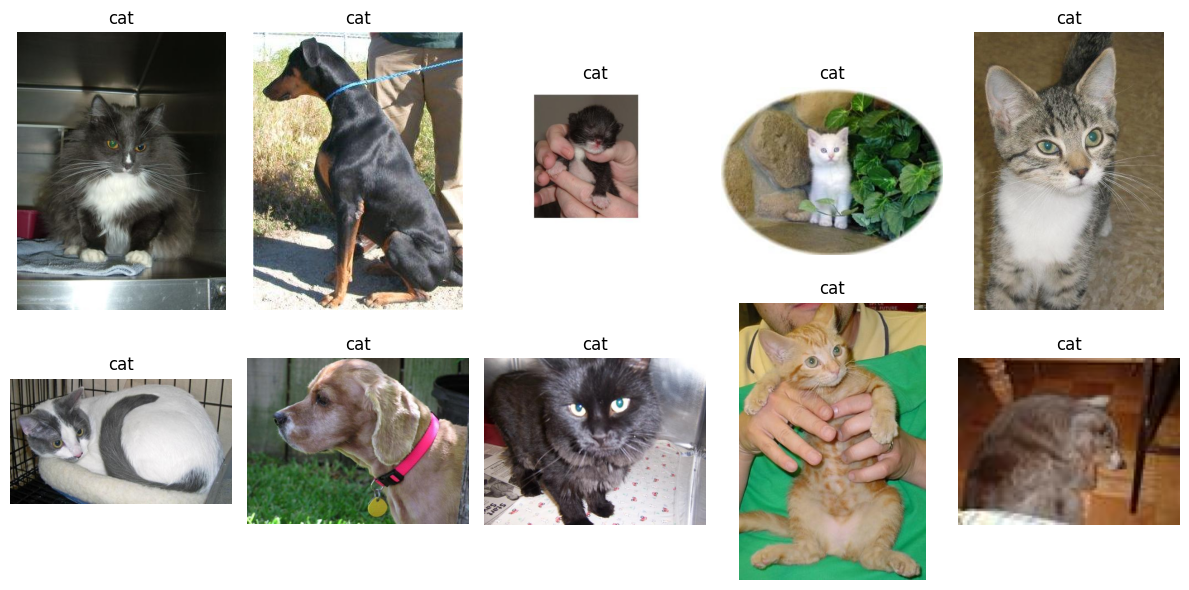

In [31]:
class_ = classes = {0:'cat', 1:'dog'}
def display_image_grid(images_filepaths, predicted_labels=(), cols=5):
    rows = len(images_filepaths) // cols
    figure, ax = plt.subplots(nrows=rows, ncols=cols, figsize=(12, 6))
    for i, image_filepath in enumerate(images_filepaths):
        image = cv2.imread(image_filepath)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        a = random.choice(res['id'].values)
        label = res.loc[res['id'] == a, 'label'].values[0]

        if label > 0.5:
            label = 1
        else:
            label = 0
        ax.ravel()[i].imshow(image)
        ax.ravel()[i].set_title(class_[label])
        ax.ravel()[i].set_axis_off()
    plt.tight_layout()
    plt.show()
display_image_grid(test_images_filepaths)